<div align="center">
<img src="../Entregables/figuras/espectros_completos.png" alt="Espectros ALMA W1 y W2 de IRAS 16293−2422" width="900">

<strong>ASTROHACK SATEM 2026 · EQUIPO SKYNTISTS</strong>

<h1>Análisis reproducible de líneas moleculares</h1>

<h3>De los espectros calibrados a la evaluación de candidatas prebióticas</h3>

**IRAS 16293−2422 B · Ventanas ALMA W1 y W2**
</div>

---

**Integrantes del equipo**

Angel Gabriel Jiménez Isidro  
Carlos Manuel Martínez Hernández  
Luis Gustavo Cons  
Paola Díaz Arellano  
Yarek Alejandro Olivares Meneses  

**Enfoque científico**  
Evaluamos la compatibilidad de rasgos espectrales con transiciones moleculares, documentando el método, las alternativas y los límites de la evidencia. Los resultados son exploratorios: una coincidencia no constituye una identificación confirmada.

---

Este cuaderno analiza los espectros calibrados de IRAS 16293−2422. La meta no es contar coincidencias, sino evaluar si un conjunto de rasgos independientes respalda una hipótesis molecular. Líneas mezcladas, ruido, velocidad, ancho instrumental y alternativas limitan la fuerza de cada candidata.

**Alcance:** catálogos educativos locales, ventanas W1/W2 y posiciones A, B_pico y B_offset. El catálogo es una selección y no contiene todas las especies posibles. Los productos son datos procesados para el reto, no una nueva calibración.

El cuaderno produce tablas de inspección, figuras PNG y `Entregables/Campos_de_evidencia.csv`. Las decisiones se marcan como tentativas o insuficientes cuando los datos no permiten confirmar una identificación. Ejecuta de arriba abajo desde cualquier directorio del paquete.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from IPython.display import display

C_KMS = 299792.458
V_RADIO_B_KMS = 2.7  # valor inicial de la guía para B; incertidumbre sistemática: ±1 km/s
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "espectros/W1_espectros.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("No encuentro espectros/W1_espectros.csv; abre el notebook dentro del paquete Skyntists.")
OUT = ROOT / "Entregables"
FIG = OUT / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .22})

espectros = {w: pd.read_csv(ROOT / f"espectros/W{w}_espectros.csv") for w in (1, 2)}
catalogo = pd.read_csv(ROOT / "catalogos/catalogo_local_prebioticas.csv", dtype={"entrada": str})
# Verificaciones de estructura, unidades y muestreo
for w, d in espectros.items():
    assert {"frecuencia_LSRK_GHz", "B_offset_Jy_beam", "B_pico_Jy_beam", "A_Jy_beam"} <= set(d.columns)
    f = d.frecuencia_LSRK_GHz.to_numpy()
    assert np.all(np.isfinite(f)) and np.all(np.diff(f) > 0), f"Eje de frecuencia no válido W{w}"
    assert len(d) > 100
print(f"Paquete: {ROOT} | canales W1/W2: {[len(espectros[w]) for w in (1,2)]}")
print(f"Catálogo prebiótico: {len(catalogo)} transiciones, {catalogo.especie.nunique()} especies/estados")
print("El catálogo no es exhaustivo; log10_I_300K no es Aij ni una intensidad predicha para esta fuente.")

Paquete: C:\Users\agent\OneDrive\Pictures\AstroHack\Skyntists | canales W1/W2: [1918, 1918]
Catálogo prebiótico: 221 transiciones, 12 especies/estados
El catálogo no es exhaustivo; log10_I_300K no es Aij ni una intensidad predicha para esta fuente.


## 1. Verificación de la extracción contra los cubos

La guía especifica que B_offset representa el píxel (x,y)=(54,46). Cuando se incluyen los cubos FITS, cotejamos cada canal del píxel con su CSV, incluidas unidades y marco espectral. Esto valida la transferencia de datos; no vuelve a calibrar el cubo.

In [2]:
from astropy.io import fits

verificacion_cubos = {}
for w in (1, 2):
    ruta = ROOT / f"cubos/W{w}_IRAS16293.fits"
    if not ruta.exists():
        verificacion_cubos[w] = "no disponible"
        print(f"W{w}: no hay FITS; se usa la extracción CSV suministrada.")
        continue
    with fits.open(ruta, memmap=True) as hdus:
        cube = hdus[0].data
        header = hdus[0].header
        assert cube.ndim == 3 and cube.shape[0] == len(espectros[w]), f"Ejes inesperados W{w}: {cube.shape}"
        assert header.get("BUNIT") == "Jy/beam", f"Unidad inesperada W{w}: {header.get('BUNIT')}"
        assert header.get("SPECSYS") == "LSRK", f"Marco inesperado W{w}: {header.get('SPECSYS')}"
        pixel = np.asarray(cube[:, 46, 54], dtype=float)
    coincide = np.allclose(pixel, espectros[w].B_offset_Jy_beam.to_numpy(), rtol=1e-7, atol=1e-9)
    assert coincide, f"B_offset W{w} no coincide con el píxel (54,46)"
    verificacion_cubos[w] = "coincide"
    print(f"W{w}: cubo {cube.shape}, Jy/beam, SPECSYS=LSRK; píxel (54,46) coincide con B_offset.")

W1: cubo (1918, 64, 64), Jy/beam, SPECSYS=LSRK; píxel (54,46) coincide con B_offset.
W2: cubo (1918, 64, 64), Jy/beam, SPECSYS=LSRK; píxel (54,46) coincide con B_offset.


## 1. Inspección del espectro

La señal está en Jy/beam. Se muestran las tres extracciones disponibles sin desplazar ni reescalar los datos. Las dos ventanas tienen haces diferentes; sus amplitudes no deben compararse como abundancias.

herramientas\Inicio_AstroHack.ipynb#cell-5:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


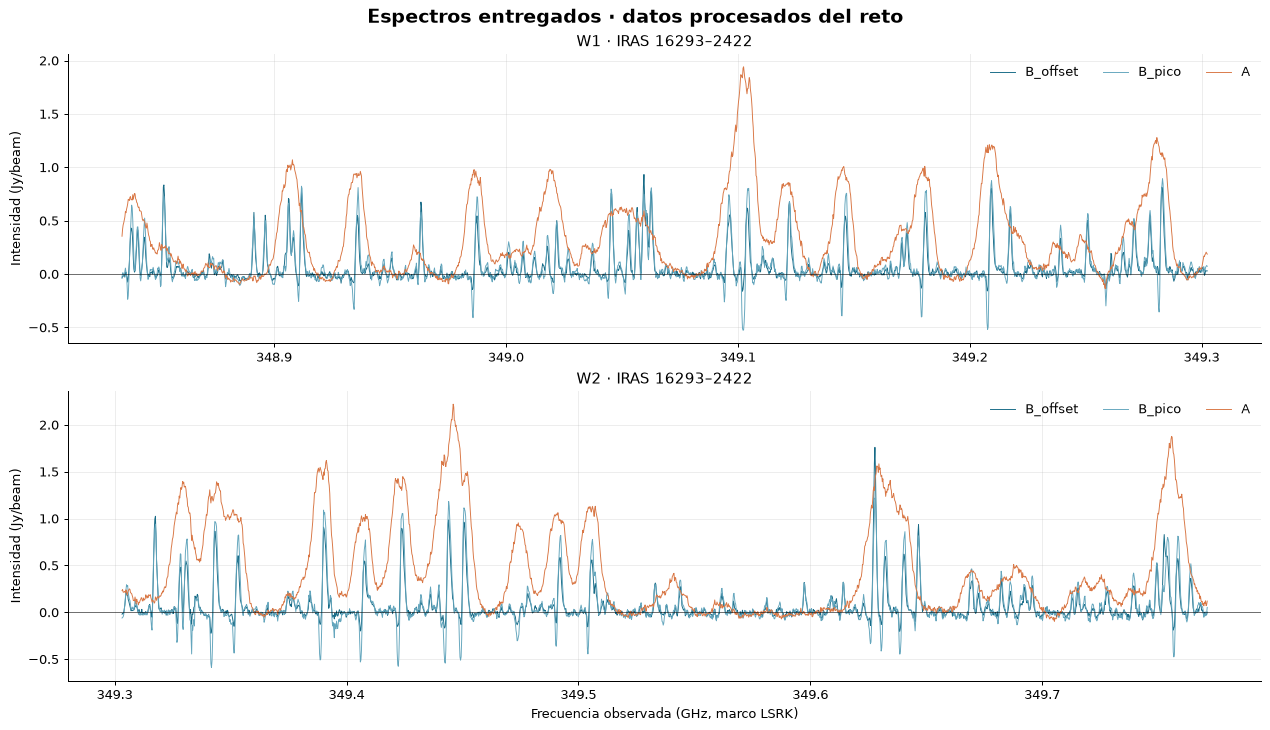

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False, layout="constrained")
colores = {"B_offset_Jy_beam":"#176B87", "B_pico_Jy_beam":"#64A6BD", "A_Jy_beam":"#D97745"}
for w, ax in zip((1,2), axes):
    d = espectros[w]
    for col, color in colores.items():
        ax.plot(d.frecuencia_LSRK_GHz, d[col], lw=.75, color=color, label=col.replace("_Jy_beam", ""))
    ax.axhline(0, color="black", lw=.7, alpha=.6)
    ax.set(title=f"W{w} · IRAS 16293–2422", ylabel="Intensidad (Jy/beam)")
    ax.legend(ncol=3, frameon=False, loc="upper right")
axes[-1].set_xlabel("Frecuencia observada (GHz, marco LSRK)")
fig.suptitle("Espectros entregados · datos procesados del reto", fontsize=15, weight="bold")
fig.savefig(FIG / "espectros_completos.png", bbox_inches="tight")
plt.show()

## 2. Ruido robusto y rasgos observados

El ruido se estima con la desviación robusta de diferencias entre canales consecutivos (MAD/√2). Esto reduce la influencia de líneas anchas, pero los canales pueden estar correlacionados por el procesamiento: el SNR es una guía y no sustituye el error de calibración ni un análisis de covarianza. La búsqueda marca máximos de prominencia ≥ 5σ estimados; se inspeccionan también en contexto.

W1: Δν=0.2441 MHz; σ_aprox=0.0205 Jy/beam; rasgos candidatos=64
W2: Δν=0.2441 MHz; σ_aprox=0.0231 Jy/beam; rasgos candidatos=56
herramientas\Inicio_AstroHack.ipynb#cell-7:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


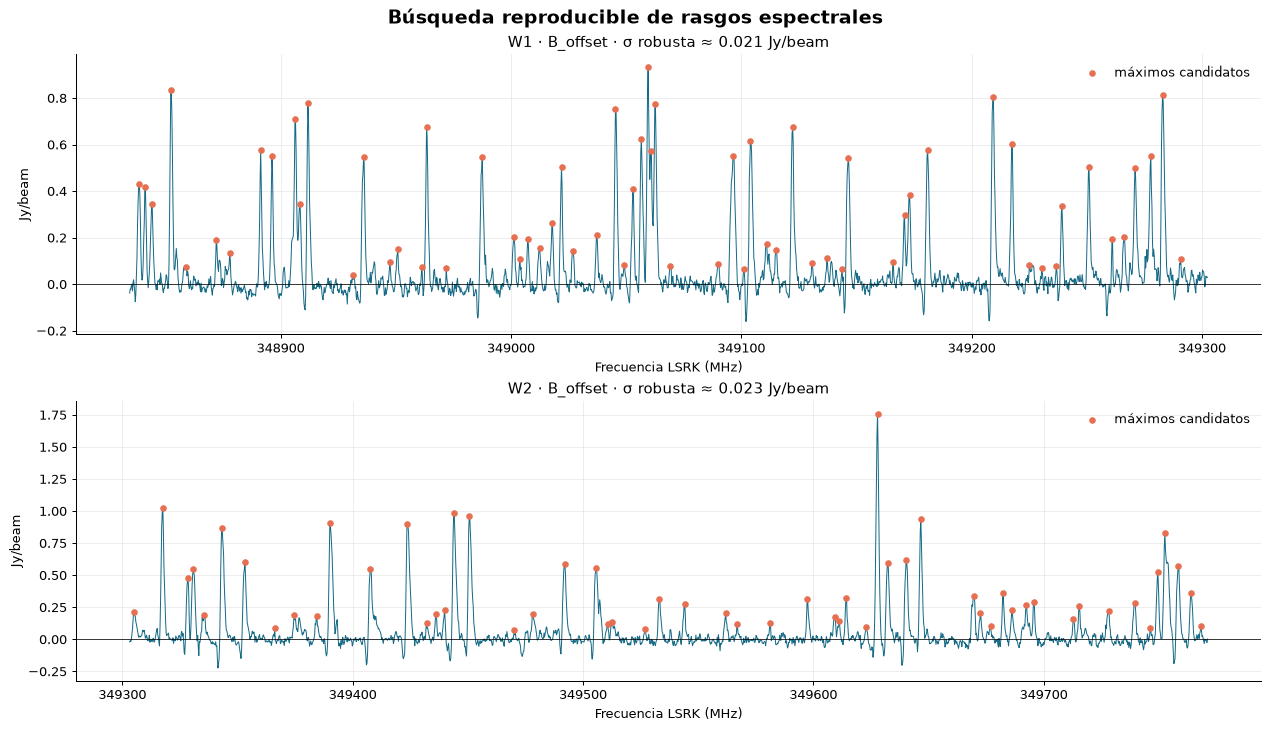

In [4]:
def sigma_diferencias(y):
    """Estimador robusto aproximado del ruido por canal; presupone diferencias locales estacionarias."""
    dy = np.diff(np.asarray(y, float))
    med = np.median(dy)
    return 1.4826 * np.median(np.abs(dy-med)) / np.sqrt(2)

picos = {}
for w, d in espectros.items():
    f = d.frecuencia_LSRK_GHz.to_numpy() * 1000
    y = d.B_offset_Jy_beam.to_numpy()
    sigma = sigma_diferencias(y)
    idx, props = find_peaks(y, prominence=max(5*sigma, .03), distance=3)
    p = pd.DataFrame({"canal": idx, "frecuencia_pico_LSRK_MHz": f[idx],
                      "pico_Jy_beam": y[idx], "prominencia_Jy_beam": props["prominences"]})
    p["sigma_aprox_Jy_beam"] = sigma
    p["SNR_prominencia_aprox"] = p.prominencia_Jy_beam / sigma
    picos[w] = p.sort_values("frecuencia_pico_LSRK_MHz").reset_index(drop=True)
    print(f"W{w}: Δν={np.median(np.diff(f)):.4f} MHz; σ_aprox={sigma:.4f} Jy/beam; rasgos candidatos={len(p)}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), layout="constrained")
for w, ax in zip((1,2), axes):
    d=espectros[w]; f=d.frecuencia_LSRK_GHz.to_numpy()*1000; y=d.B_offset_Jy_beam.to_numpy()
    ax.plot(f, y, color="#176B87", lw=.8)
    ax.scatter(picos[w].frecuencia_pico_LSRK_MHz, picos[w].pico_Jy_beam,
               s=18, color="#E76F51", zorder=3, label="máximos candidatos")
    ax.axhline(0,color="black",lw=.6)
    ax.set(title=f"W{w} · B_offset · σ robusta ≈ {picos[w].sigma_aprox_Jy_beam.iloc[0]:.3f} Jy/beam",
           xlabel="Frecuencia LSRK (MHz)",ylabel="Jy/beam")
    ax.legend(frameon=False)
fig.suptitle("Búsqueda reproducible de rasgos espectrales", fontsize=15, weight="bold")
fig.savefig(FIG / "picos_detectados.png", bbox_inches="tight")
plt.show()

## 3. Comparación con frecuencias de reposo

Se aplica una sola vez la convención de velocidad radio, ν_obs = ν_rest(1−v/c). Para B usamos 2.7 km/s como punto de partida de la guía y propagamos ±1 km/s como incertidumbre de velocidad de exploración. La tolerancia de asociación combina este margen con el error de laboratorio y el muestreo (medio canal). Cero o ausente en incertidumbre de catálogo significa “no informado”, no una frecuencia exacta. Los resultados son asociaciones para inspección: los duplicados/blends deben agruparse y no cuentan como evidencias independientes.

In [5]:
def tabla_coincidencias(ventana, velocidad_kms=V_RADIO_B_KMS, margen_vel_kms=1.0):
    d = espectros[ventana]
    f = d.frecuencia_LSRK_GHz.to_numpy()*1000
    paso = float(np.median(np.diff(f)))
    rows=[]
    for r in catalogo.itertuples(index=False):
        esperado = r.frecuencia_reposo_MHz*(1-velocidad_kms/C_KMS)
        if esperado < f.min() or esperado > f.max():
            continue
        ip = int(np.argmin(abs(f-esperado)))
        p = picos[ventana]
        if p.empty: continue
        j = int(np.argmin(abs(p.frecuencia_pico_LSRK_MHz.to_numpy()-esperado)))
        peak = p.iloc[j]
        delta = float(peak.frecuencia_pico_LSRK_MHz-esperado)
        sigma_cat = float(r.incertidumbre_MHz) if pd.notna(r.incertidumbre_MHz) and r.incertidumbre_MHz>0 else np.nan
        tol = np.sqrt((esperado*margen_vel_kms/C_KMS)**2 + (sigma_cat if np.isfinite(sigma_cat) else 0)**2 + (paso/2)**2)
        # Limitar asociación automatizada para que una incertidumbre de catálogo enorme no sea un pase libre.
        tol = min(max(tol, paso), 1.5)
        if abs(delta) <= tol and peak.SNR_prominencia_aprox >= 5:
            rows.append({"ventana":f"W{ventana}","especie":r.especie,"catalogo":r.catalogo,
                "entrada":r.entrada,"frecuencia_reposo_MHz":r.frecuencia_reposo_MHz,
                "frecuencia_predicha_LSRK_MHz":esperado,"frecuencia_pico_LSRK_MHz":peak.frecuencia_pico_LSRK_MHz,
                "residuo_MHz":delta,"tolerancia_asociacion_MHz":tol,"sigma_catalogo_MHz":sigma_cat,
                "prominencia_Jy_beam":peak.prominencia_Jy_beam,"SNR_aprox":peak.SNR_prominencia_aprox,
                "grupo_rasgo":f"{ventana}-{int(peak.canal)}"})
    return pd.DataFrame(rows)

coincidencias = pd.concat([tabla_coincidencias(w) for w in (1,2)], ignore_index=True)
coincidencias = coincidencias.sort_values(["ventana","frecuencia_pico_LSRK_MHz","residuo_MHz"])
print(f"Asociaciones catálogo-pico: {len(coincidencias)}; rasgos únicos: {coincidencias.groupby('ventana').grupo_rasgo.nunique().to_dict()}")
display(coincidencias.head(30))

Asociaciones catálogo-pico: 107; rasgos únicos: {'W1': 34, 'W2': 30}
   ventana     especie catalogo  ... prominencia_Jy_beam  SNR_aprox  grupo_rasgo
0       W1      CH3CHO      JPL  ...            0.399679  19.487493         1-27
4       W1      C2H5OH      JPL  ...            0.360210  17.563066         1-40
3       W1      C2H5OH      JPL  ...            0.360210  17.563066         1-40
2       W1      C2H5OH      JPL  ...            0.360210  17.563066         1-40
1       W1      C2H5CN     CDMS  ...            0.360210  17.563066         1-40
5       W1      CH3CHO      JPL  ...            0.910287  44.383673         1-74
7       W1      CH3CHO      JPL  ...            0.107953   5.263548        1-101
6       W1      C2H5OH      JPL  ...            0.107953   5.263548        1-101
8       W1  CH2(OH)CHO     CDMS  ...            0.776390  37.855145        1-294
9       W1       CH3CN     CDMS  ...            0.156596   7.635318        1-303
10      W1       CH3CN     CDMS  ...    

## 4. Hipótesis, perfiles y tabla de evidencia

Para que el ejercicio sea auditable, se fijan dos hipótesis de moléculas con varias transiciones en la cobertura: CH₃CN (acetonitrilo) y CH₃CHO (acetaldehído). Los seis rasgos se ajustan automáticamente cerca de las transiciones de catálogo indicadas; las transiciones a menos de un canal del mismo máximo se consideran un grupo/blend. Se conserva una fila de alternativa para glicina: su coincidencia no basta para identificarla.

El ajuste gaussiano más constante es descriptivo, no prueba molecular. La incertidumbre del área es una aproximación basada en el ruido empírico local y el muestreo, sin covarianza de canales ni incertidumbres de calibración. Revisa cada figura y modifica las decisiones si la inspección lo requiere.

herramientas\Inicio_AstroHack.ipynb#cell-11:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
Evidencia guardada: C:\Users\agent\OneDrive\Pictures\AstroHack\Skyntists\Entregables\Campos_de_evidencia.csv
      equipo  ...                    archivo_figura
0  Skyntists  ...  figuras/perfil_W1-349021.940.png
1  Skyntists  ...  figuras/perfil_W1-349122.278.png
2  Skyntists  ...  figuras/perfil_W2-349343.219.png
3  Skyntists  ...  figuras/perfil_W1-348852.514.png
4  Skyntists  ...  figuras/perfil_W2-349317.585.png
5  Skyntists  ...  figuras/perfil_W2-349752.625.png
6  Skyntists  ...      figuras/picos_detectados.png

[7 rows x 21 columns]


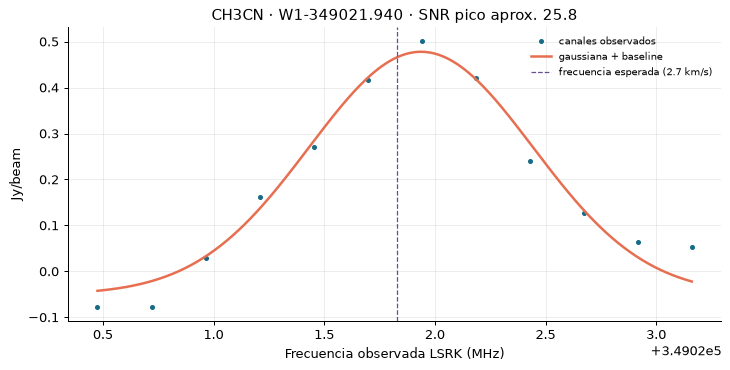

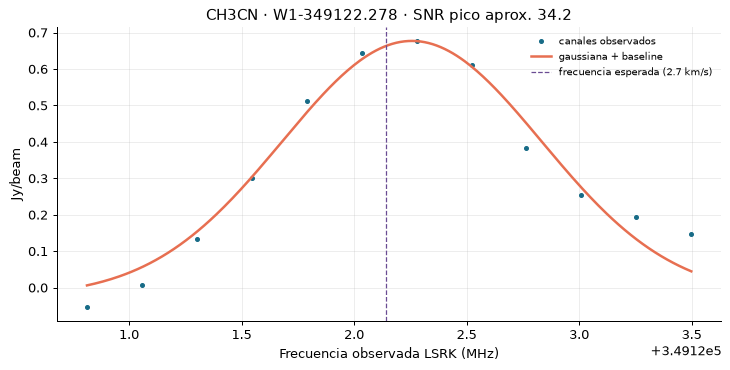

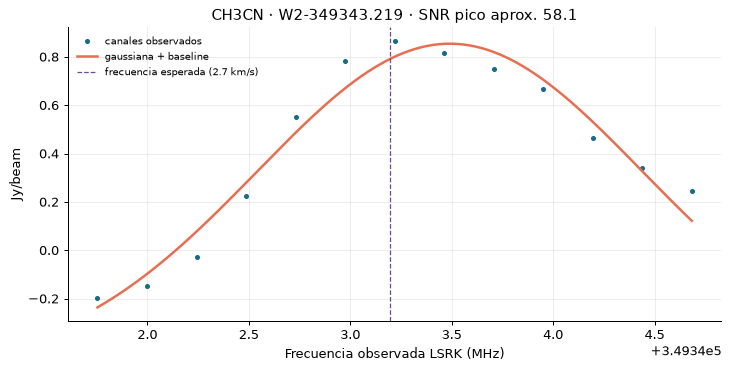

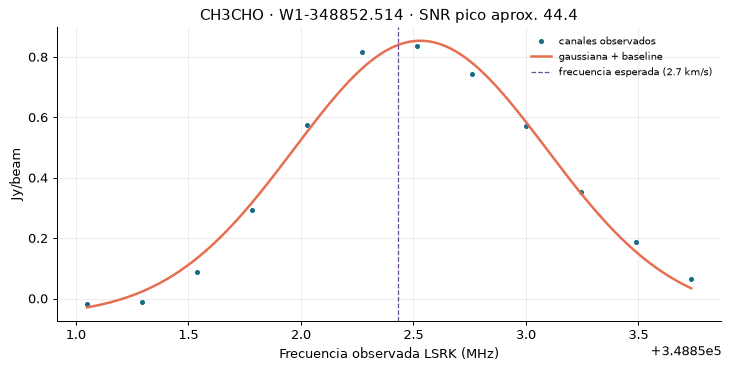

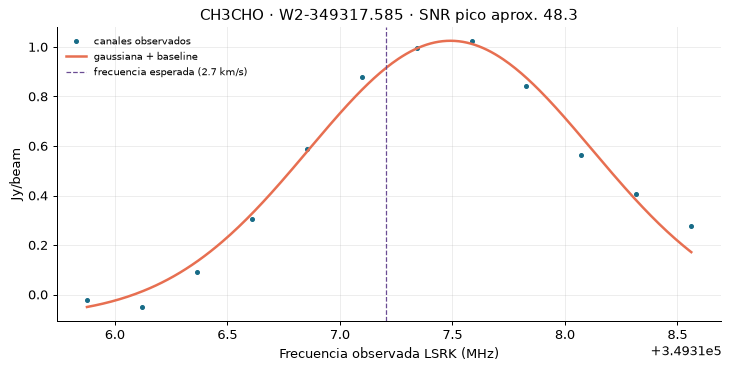

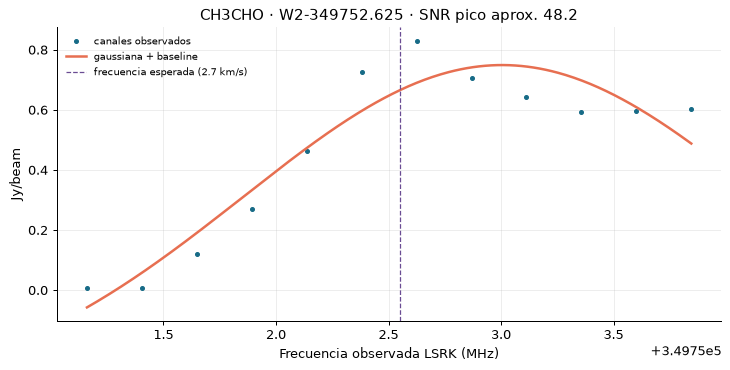

In [6]:
# Tres rasgos por hipótesis, seleccionados dentro de las dos coberturas y visibles en B_offset.
SELECCION = [
 (1,"CH3CN","CDMS","41505",349024.9709,"W1-349021.940"),
 (1,"CH3CN","CDMS","41505",349125.2874,"W1-349122.278"),
 (2,"CH3CN","CDMS","41505",349346.3430,"W2-349343.219"),
 (1,"CH3CHO","JPL","044003",348855.5714,"W1-348852.514"),
 (2,"CH3CHO","JPL","044003",349320.3515,"W2-349317.585"),
 (2,"CH3CHO","JPL","044003",349755.7020,"W2-349752.625"),
]
# Un pico para cada característica: ventana local ±1.5 MHz alrededor de frecuencia predicha.
def medir_rasgo(w, especie, catalogo_id, entrada, nu_rest, grupo):
    d=espectros[w]; f=d.frecuencia_LSRK_GHz.to_numpy()*1000; y=d.B_offset_Jy_beam.to_numpy()
    pred=nu_rest*(1-V_RADIO_B_KMS/C_KMS)
    sel=np.abs(f-pred)<=1.5
    if sel.sum()<9: raise ValueError(f"Pocos canales en {grupo}")
    x=f[sel]; z=y[sel]
    sigma=sigma_diferencias(y)
    def gauss(x,a,mu,sd,b): return b+a*np.exp(-.5*((x-mu)/sd)**2)
    p0=[max(z)-np.median(z), x[np.argmax(z)], .7, np.median(z)]
    pars,cov=curve_fit(gauss,x,z,p0=p0,bounds=([0,x.min(),.08,-np.inf],[np.inf,x.max(),3,np.inf]),maxfev=20000)
    a,mu,sd,b=pars
    fwhm_mhz=2*np.sqrt(2*np.log(2))*sd
    # v radio relativo a la frecuencia en reposo seleccionada
    fwhm_kms=C_KMS*fwhm_mhz/nu_rest
    area_jy_beam_kms=(a*sd*np.sqrt(2*np.pi))*C_KMS/nu_rest
    snr=a/sigma if sigma>0 else np.nan
    fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
    ax.plot(x,z,"o",ms=3,color="#176B87",label="canales observados")
    xx=np.linspace(x.min(),x.max(),300); ax.plot(xx,gauss(xx,*pars),color="#E76F51",lw=2,label="gaussiana + baseline")
    ax.axvline(pred,color="#6A4C93",ls="--",lw=1,label="frecuencia esperada (2.7 km/s)")
    ax.set(xlabel="Frecuencia observada LSRK (MHz)",ylabel="Jy/beam",title=f"{especie} · {grupo} · SNR pico aprox. {snr:.1f}")
    ax.legend(frameon=False,fontsize=8)
    fn=f"perfil_{grupo}.png"; fig.savefig(FIG/fn,bbox_inches="tight"); plt.show()
    return {"frecuencia_pico_LSRK_MHz":mu,"v_radio_kms":C_KMS*(1-mu/nu_rest),"FWHM_kms":fwhm_kms,
      "baseline_Jy_beam":b,"sigma_Jy_beam":sigma,"SNR":snr,"area_Jy_beam_kms":area_jy_beam_kms,
      "metodo_incertidumbre":"sigma robusta de primeras diferencias / sqrt(2); error de área aproximado sigma*sqrt(Nchan)*dv; no incluye correlación/calibración",
      "archivo_figura":f"figuras/{fn}"}

mediciones=[]
for w,esp,catalogo_id,entrada,nu_rest,grupo in SELECCION:
    m=medir_rasgo(w,esp,catalogo_id,entrada,nu_rest,grupo)
    row={"equipo":"Skyntists","hipotesis":f"Presencia de {esp}","especie":esp,"catalogo":catalogo_id,"entrada":entrada,
      "frecuencia_reposo_MHz":nu_rest,"ventana":f"W{w}","posicion":"B_offset","grupo_rasgo":grupo,
      "mezcla":"Sí; catálogo local incompleto y se solapan transiciones dentro del haz/canal",
      "alternativas":"Otras transiciones del catálogo y especies no incluidas; ver tabla de coincidencias",
      "decision":"Tentativa; varias líneas compatibles, sin modelado LTE ni catálogo exhaustivo",
      **m}
    # Área e incertidumbre formal simplificada se explicitan en lugar de afirmar precisión excesiva.
    mediciones.append(row)
# Una hipótesis alternativa se registra como insuficiente, sin inventar una medición de línea.
mediciones.append({"equipo":"Skyntists","hipotesis":"Asignación de pico congestionado a glicina-I","especie":"Glycine-I","catalogo":"CDMS","entrada":"075511",
 "frecuencia_reposo_MHz":348965.1769,"ventana":"W1","posicion":"B_offset","frecuencia_pico_LSRK_MHz":348963.3490,
 "v_radio_kms":C_KMS*(1-348963.3490/348965.1769),"FWHM_kms":"","baseline_Jy_beam":"","sigma_Jy_beam":"","SNR":"","area_Jy_beam_kms":"",
 "metodo_incertidumbre":"No se ajusta: rasgo congestionado; incertidumbre de frecuencia de catálogo 0.766 MHz y alternativas cercanas",
 "grupo_rasgo":"W1-526","mezcla":"Sí","alternativas":"CH3CHO y otras transiciones del catálogo/no incluidas; búsqueda local no distingue componentes",
 "decision":"Insuficiente: coincidencia aislada no confirma glicina; requiere más transiciones independientes y ajuste conjunto",
 "archivo_figura":"figuras/picos_detectados.png"})

evidencia=pd.DataFrame(mediciones)
columnas=["equipo","hipotesis","especie","catalogo","entrada","frecuencia_reposo_MHz","ventana","posicion","frecuencia_pico_LSRK_MHz","v_radio_kms","FWHM_kms","baseline_Jy_beam","sigma_Jy_beam","SNR","area_Jy_beam_kms","metodo_incertidumbre","grupo_rasgo","mezcla","alternativas","decision","archivo_figura"]
evidencia=evidencia.reindex(columns=columnas)
evidencia.to_csv(OUT/"Campos_de_evidencia.csv",index=False,float_format="%.7f")
print(f"Evidencia guardada: {OUT/'Campos_de_evidencia.csv'}")
display(evidencia)

## 5. Coeficientes de Einstein: cuándo sirven

El coeficiente espontáneo Aᵢⱼ (s⁻¹) es la probabilidad por unidad de tiempo de una transición de emisión espontánea. Junto con Bᵢⱼ/Bⱼᵢ y población de niveles, entra en ecuaciones de transferencia radiativa y en modelos LTE/no-LTE; ayuda a predecir intensidades relativas junto con degeneración, energía, temperatura, opacidad y función de partición. **No identifica por sí solo una molécula ni sustituye la frecuencia observada.**

La guía del reto confirma que el CSV local no incluye Aᵢⱼ y que `log10_I_300K_nm2_MHz` no es log(Aᵢⱼ). Por rigor no derivamos Aᵢⱼ de esa columna ni mezclamos convenciones. El siguiente paso, si se desea modelar intensidades, es recuperar los parámetros completos de la entrada CDMS/JPL exacta, conservar versión/fecha y unidades y calcular un espectro sintético con herramientas como CASSIS; se deben comparar líneas múltiples, no ajustar abundancia a partir de un solo pico.

## 6. Límites y reproducibilidad

- El estimador de ruido y SNR ignora correlación entre canales, calibración absoluta y errores sistemáticos del baseline.
- Velocidad inicial B = 2.7 km/s (±1 km/s de exploración); refínala con un conjunto de líneas limpias. No aplicar esta velocidad a A.
- Los anchos de haz W1/W2 son distintos; no se infieren abundancias desde amplitudes de un píxel.
- El catálogo es una selección educativa. Ausencia de coincidencia no implica ausencia de molécula; coincidencia no confirma presencia.
- Los productos ALMA se entregan calibrados/procesados y requieren evaluación adicional para investigación publicable.
- El análisis genera `Entregables/Campos_de_evidencia.csv` y figuras bajo `Entregables/figuras/`. Registra cambios de hipótesis y revisa las figuras antes de entregar.

**Uso de IA:** se utilizó Codex para estructurar y editar el análisis y el texto. La selección e interpretación final de candidatas debe ser revisada y defendida por el equipo. Datos: ADS/JAO.ALMA#2013.1.00278.S, productos ARI-L. Referencias espectroscópicas: entradas CDMS/JPL indicadas en el CSV; contexto científico: Jørgensen et al. 2016, A&A 595, A117.